# Customer Churn Prediction using Machine Learning

**Goal:** Predict whether a telecom customer will leave (churn) or stay, using the Telco Customer Churn dataset (Kaggle / IBM).

**Steps:** Load data → Explore → Clean → Encode → Train models → Evaluate → Feature importance → Predict for a new customer

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

## 2. Load the dataset

This tries to download the dataset automatically. If that fails, it asks you to upload the CSV manually.
(Kaggle dataset name: **Telco Customer Churn** by blastchar, file `WA_Fn-UseC_-Telco-Customer-Churn.csv`.)

In [2]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

try:
    df = pd.read_csv(url)
    print("Loaded from URL")
except Exception as e:
    print("Auto-download failed:", e)
    print("Please upload the CSV file from Kaggle...")
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(list(uploaded.keys())[0])

print(df.shape)
df.head()

Loaded from URL
(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Explore the data

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
print("Missing values:\n", df.isnull().sum().sum())
print("\nChurn counts:")
print(df["Churn"].value_counts())
print("\nChurn %:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Missing values:
 0

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn %:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


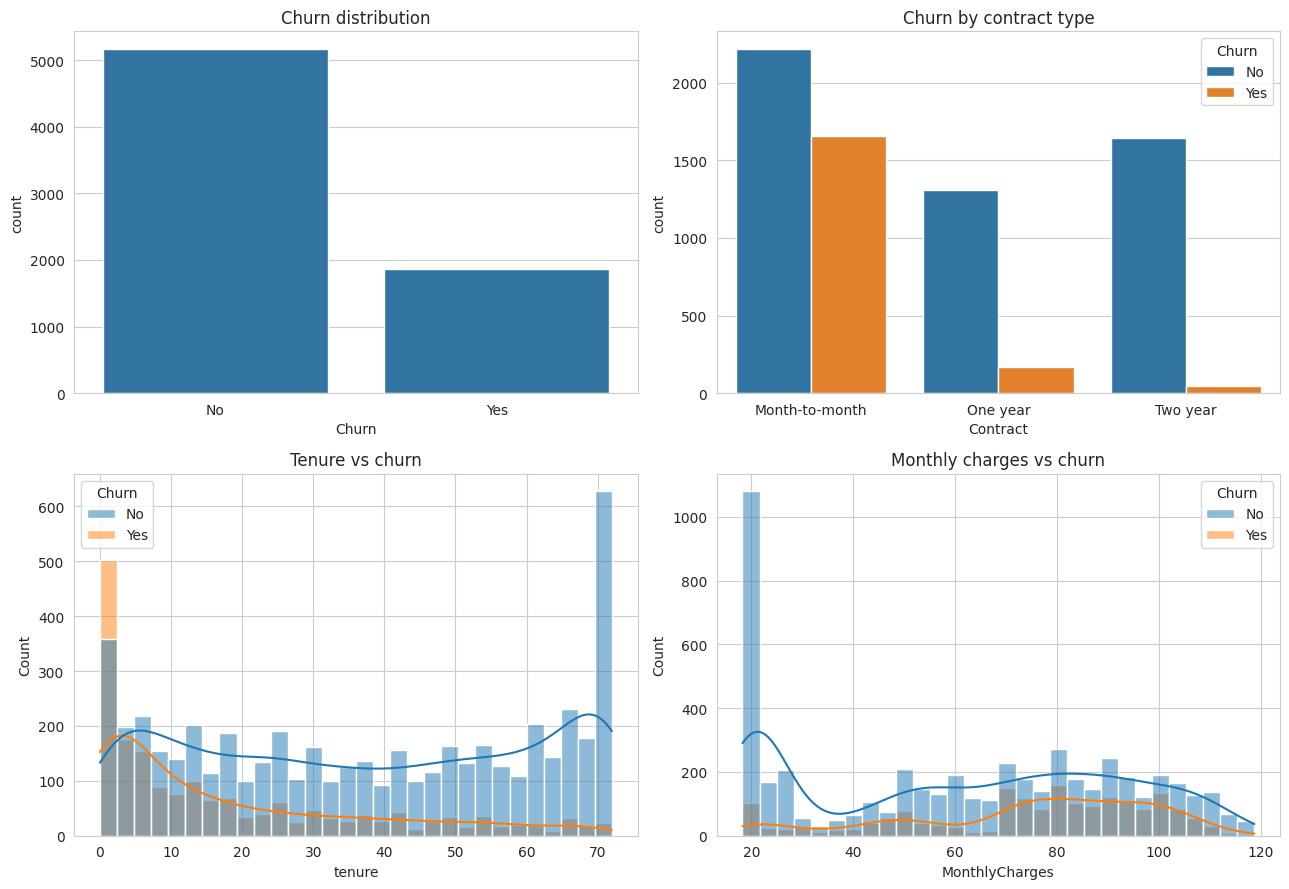

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.countplot(data=df, x="Churn", ax=axes[0, 0])
axes[0, 0].set_title("Churn distribution")

sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0, 1])
axes[0, 1].set_title("Churn by contract type")

sns.histplot(data=df, x="tenure", hue="Churn", bins=30, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Tenure vs churn")

sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=30, kde=True, ax=axes[1, 1])
axes[1, 1].set_title("Monthly charges vs churn")

plt.tight_layout()
plt.show()

## 4. Clean the data

- `TotalCharges` is stored as text (blank for brand-new customers) → convert to numbers
- `customerID` is just an identifier → drop it

In [6]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

df = df.drop("customerID", axis=1)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

df.head()

Missing TotalCharges: 11


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 5. Encode categorical columns

In [7]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

# One-hot encode all text columns
X = pd.get_dummies(X, drop_first=True)

print("Final feature count:", X.shape[1])
X.head()

Final feature count: 30


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


## 6. Train / test split and scaling

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (5634, 30)  Test: (1409, 30)


## 7. Train models

Only ~26% of customers churn, so the data is imbalanced. We use `class_weight="balanced"` to help the models pay attention to churners.

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

results = []
trained = {}

for name, model in models.items():
    # Logistic Regression needs scaled data; tree models don't
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        pred = model.predict(X_test_scaled)
        proba = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        proba = model.predict_proba(X_test)[:, 1]

    trained[name] = (model, pred, proba)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.739,0.505,0.781,0.613,0.841
Random Forest,0.789,0.630,0.500,0.557,0.825
Gradient Boosting,0.799,0.654,0.516,0.577,0.843


## 8. Evaluate the best model

In [10]:
best_name = results_df["ROC-AUC"].idxmax()
best_model, best_pred, best_proba = trained[best_name]
print("Best model (by ROC-AUC):", best_name)
print()
print(classification_report(y_test, best_pred, target_names=["Stayed", "Churned"]))

Best model (by ROC-AUC): Gradient Boosting

              precision    recall  f1-score   support

      Stayed       0.84      0.90      0.87      1035
     Churned       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



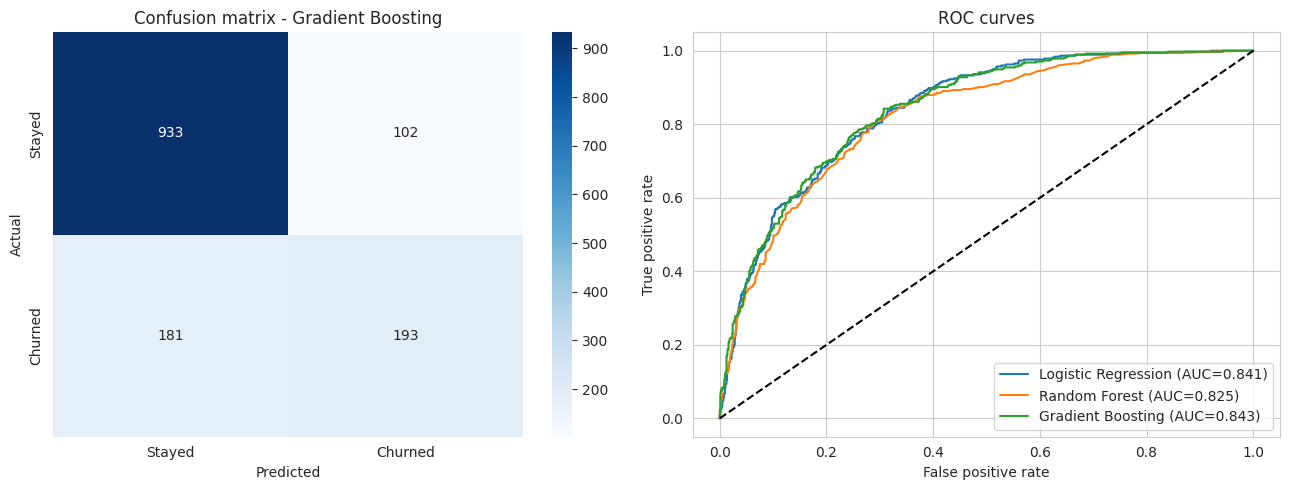

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion matrix
cm = confusion_matrix(y_test, best_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
axes[0].set_title(f"Confusion matrix - {best_name}")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# ROC curves for all models
for name, (m, p, pr) in trained.items():
    fpr, tpr, _ = roc_curve(y_test, pr)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, pr):.3f})")
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("ROC curves")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Which features drive churn?

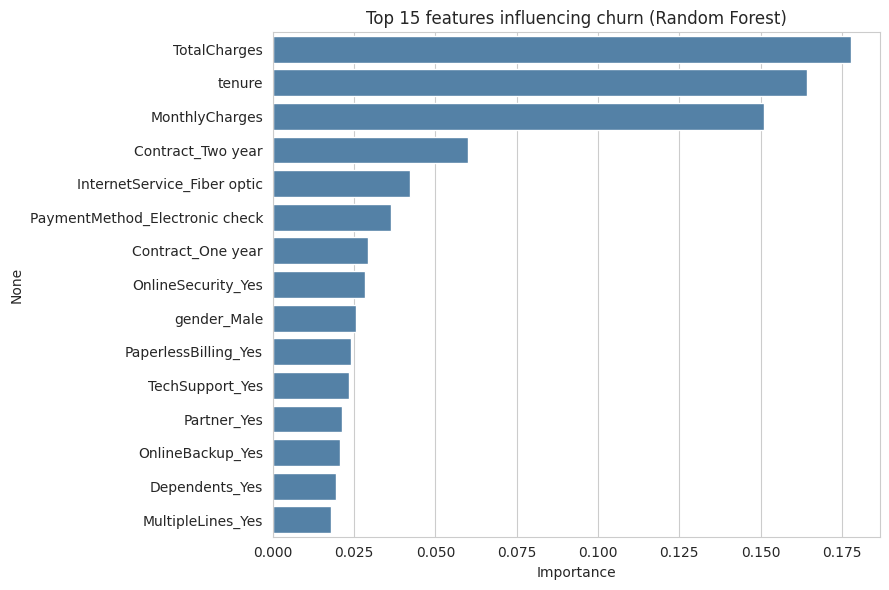

In [12]:
rf = trained["Random Forest"][0]
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=importances.values, y=importances.index, color="steelblue")
plt.title("Top 15 features influencing churn (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 10. Save the model

In [13]:
joblib.dump(best_model, "churn_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(list(X.columns), "feature_columns.pkl")
print("Saved: churn_model.pkl, scaler.pkl, feature_columns.pkl")

# To download them to your computer:
# from google.colab import files
# files.download("churn_model.pkl")

Saved: churn_model.pkl, scaler.pkl, feature_columns.pkl


## 11. Predict churn for a new customer

In [14]:
# Pick a customer from the test set and see the prediction
sample = X_test.iloc[[0]]

if best_name == "Logistic Regression":
    sample_in = scaler.transform(sample)
else:
    sample_in = sample

prob = best_model.predict_proba(sample_in)[0][1]
label = "WILL CHURN" if prob >= 0.5 else "WILL STAY"

print(f"Churn probability: {prob:.2%}")
print(f"Prediction: {label}")
print(f"Actual: {'Churned' if y_test.iloc[0] == 1 else 'Stayed'}")

Churn probability: 2.23%
Prediction: WILL STAY
Actual: Stayed


## Summary

- Customers on **month-to-month contracts**, with **short tenure** and **high monthly charges**, are the most likely to churn.
- Compare the models using **Recall** and **ROC-AUC**, not just accuracy, since churners are the minority class.
- Ideas to extend: hyperparameter tuning (GridSearchCV), SMOTE for imbalance, XGBoost, or a Streamlit app to serve the model.